IQR fences: 28.50 to 80.50
IQR outliers: 0; Z-score outliers: 0


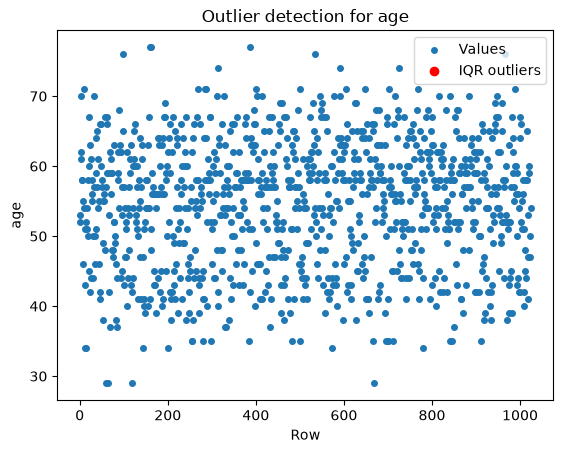

,age


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

task_name = "Task_18_Outlier_Detection"
candidates = [Path("heart.csv"), Path(task_name) / "heart.csv", Path("Heart_Disease_Tasks") / task_name / "heart.csv"]
csv_path = next(path for path in candidates if path.is_file())
df = pd.read_csv(csv_path)

column = "age"
values = df[column].dropna()
q1, q3 = values.quantile([0.25, 0.75])
iqr = q3 - q1
lower_fence, upper_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
iqr_outliers = values[(values < lower_fence) | (values > upper_fence)]
z_scores = (values - values.mean()) / values.std(ddof=0)
z_outliers = values[z_scores.abs() > 3]
print(f"IQR fences: {lower_fence:.2f} to {upper_fence:.2f}")
print(f"IQR outliers: {len(iqr_outliers)}; Z-score outliers: {len(z_outliers)}")
plt.scatter(values.index, values, s=16, label="Values")
plt.scatter(iqr_outliers.index, iqr_outliers, color="red", label="IQR outliers")
plt.xlabel("Row")
plt.ylabel(column)
plt.title(f"Outlier detection for {column}")
plt.legend()
plt.show()
display(iqr_outliers.to_frame(column))